In [1]:
import pandas as pd
import numpy as np

In [2]:
df = pd.read_csv("pce_cleaned_dataset.csv")

In [3]:
df.shape

(558, 45)

In [4]:
df.columns

Index(['ref', 'DOI', 'Donor', 'Donor PDI', 'Donor Mn (kDa)', 'Donor Mw (kDa)',
       'HOMO_D (eV)', 'LUMO_D (eV)', 'Ehl_D (eV)', 'Eg_D (eV)', 'Acceptor',
       'HOMO_A (eV)', 'LUMO_A (eV)', 'Ehl_A (eV)', 'Eg_A (eV)',
       'D:A ratio (m/m)', 'solvent', 'Active layer spin coating speed (rpm)',
       'total solids conc. (mg/mL)', 'solvent additive',
       'solvent additive conc. (% v/v)', 'active layer thickness (nm)',
       'temperature of thermal annealing', 'annealing time (min)', 'HTL',
       'HTL energy level (eV)', 'HTL thickness (nm)', 'ETL',
       'ETL energy level (eV)', 'ETL thickness (nm)',
       'hole mobility blend (cm^2 V^-1 s^-1)',
       'electron mobility blend (cm^2 V^-1 s^-1)', 'Voc (V)', 'Jsc (mA cm^-2)',
       'FF (%)', 'PCE (%)', 'hole:electron mobility ratio',
       'log hole mobility blend (cm^2 V^-1 s^-1)',
       'log electron mobility blend (cm^2 V^-1 s^-1)',
       'log hole:electron mobility ratio', 'calculated PCE (%)',
       'Donor SMILES', 'Don

In [5]:
import json
import matplotlib.pyplot as plt

emu = pd.read_csv("opv_emulator_data.csv")
space = json.load(open("search_space.json"))
emu.shape

(526, 42)

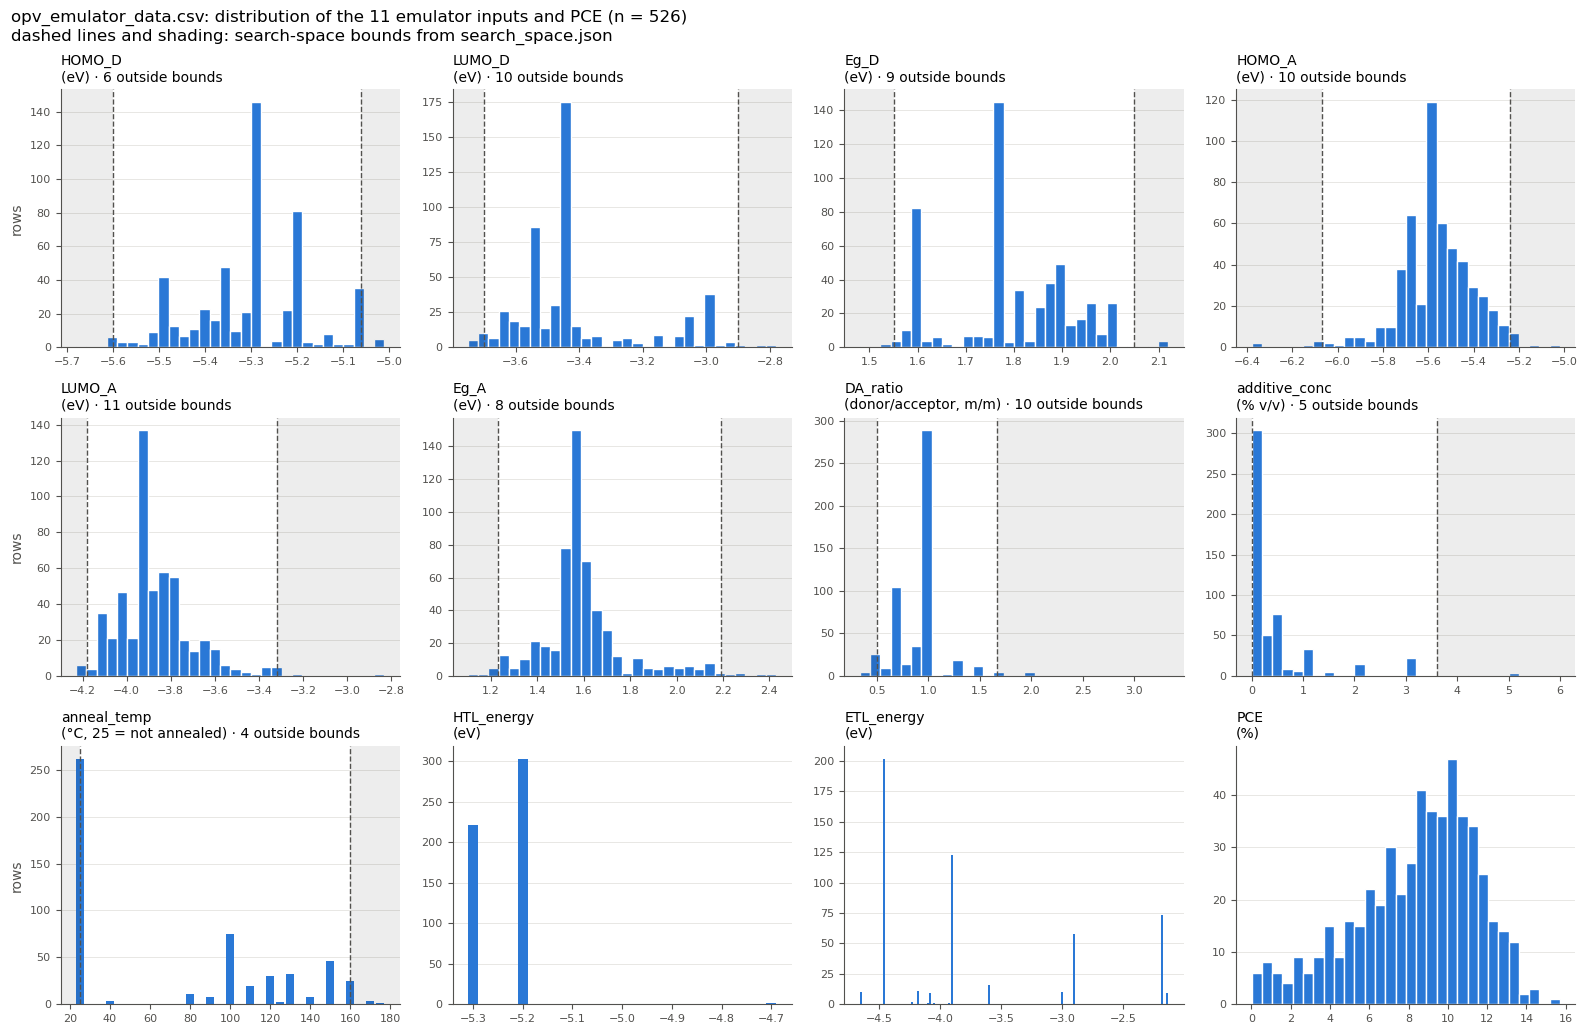

In [6]:
# Distribution of every emulator input plus the PCE target.
# The *_unit columns are the same inputs rescaled to [0, 1], so they are not plotted again.
features = space["inputs"] + ["PCE"]
units = {k: v["unit"] for k, v in space["continuous"].items()}
units["PCE"] = space["target"]["unit"]
units["anneal_temp"] = "°C, 25 = not annealed"
units["DA_ratio"] = "donor/acceptor, m/m"

BAR, MUTED, OUTSIDE = "#2a78d6", "#52514e", "#00000012"

fig, axes = plt.subplots(3, 4, figsize=(16, 10.5))
for ax, col in zip(axes.flat, features):
    x = emu[col]
    levels = np.sort(x.unique())
    if len(levels) <= 15:  # discrete setpoints: one bar per value
        counts = x.value_counts().reindex(levels)
        width = min(np.diff(levels).min() * 0.8, (levels[-1] - levels[0]) / 30)
        ax.bar(levels, counts, width=width, color=BAR)
    else:
        ax.hist(x, bins=30, color=BAR, edgecolor="white", linewidth=1)

    title = f"{col}\n({units[col]})"
    bounds = space["continuous"].get(col)
    # HTL/ETL bounds are just their outermost snap levels, so marking them adds nothing.
    if bounds and "snap_to_levels" not in bounds:
        lo, hi = bounds["lower"], bounds["upper"]
        xmin, xmax = ax.get_xlim()
        ax.axvspan(xmin, lo, color=OUTSIDE, lw=0)
        ax.axvspan(hi, xmax, color=OUTSIDE, lw=0)
        ax.set_xlim(xmin, xmax)
        for b in (lo, hi):
            ax.axvline(b, color=MUTED, ls="--", lw=1)
        n_out = int(((x < lo) | (x > hi)).sum())
        if n_out:
            title += f" · {n_out} outside bounds"
    ax.set_title(title, fontsize=10, loc="left")
    ax.spines[["top", "right"]].set_visible(False)
    ax.spines[["left", "bottom"]].set_color(MUTED)
    ax.tick_params(colors=MUTED, labelsize=8)
    ax.grid(axis="y", color="#e4e3df", lw=0.6)
    ax.set_axisbelow(True)

for ax in axes[:, 0]:
    ax.set_ylabel("rows", color=MUTED)
fig.suptitle(
    f"opv_emulator_data.csv: distribution of the {len(features) - 1} emulator inputs and PCE (n = {len(emu)})\n"
    "dashed lines and shading: search-space bounds from search_space.json",
    x=0.01, ha="left", fontsize=12,
)
fig.tight_layout()
plt.show()